In [ ]:
# The purpose of this notebook is to try a while kernel to estimate
# the noise of the data and see if that improves things
# we will try RBF + white kernel

In [1]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
path = project_root / 'data' / 'clean' / 'train_scaled.csv'

df = pd.read_csv(path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

rng = np.random.RandomState(1)
X = df[formula_cols].fillna(0).to_numpy()
y = df['Wet Strength Mean'].to_numpy()

In [7]:
# break X and y into LOOCV folds, refit the model on each fold/ print
# evaluation metrics

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import r2_score

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

kernel = 1.0 * RBF(length_scale=1e1, length_scale_bounds=(1e-10, 1e4)) + WhiteKernel(
    noise_level=1, noise_level_bounds=(1e-10, 1e1)
)

model = GaussianProcessRegressor(
    kernel=kernel, 
    normalize_y=True, 
    n_restarts_optimizer=10,
    alpha=0,
    random_state = 0
)

# LOOCV cross-validation
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score

loo = LeaveOneOut()

val_predictions = []
val_actuals = []
train_r2_scores = []

fold_num = 1
for train_idx, val_idx in loo.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # Fit model on training fold
    model.fit(X_train, y_train)
    
    # Store validation prediction
    val_pred = model.predict(X_val)
    val_predictions.append(val_pred[0])
    val_actuals.append(y_val[0])
    
    # Evaluate on training fold
    train_pred = model.predict(X_train)
    train_r2 = r2_score(y_train, train_pred)
    train_r2_scores.append(train_r2)
    
    print(f"Fold {fold_num}: Val Prediction = {val_pred[0]:.3f}, Actual = {y_val[0]:.3f}")
    fold_num += 1

# Calculate R² across ALL out-of-fold predictions
val_r2 = r2_score(val_actuals, val_predictions)

# Calculate averages
avg_train_r2 = np.mean(train_r2_scores)

# Create summary table
results_df = pd.DataFrame({
    'Error Source': ['Goal Performance', 'Train Error', 'Validation Error (LOOCV)', 'Test Error'],
    'Value': [
        'R² = .8',
        f'R² = {avg_train_r2:.3f}',
        f'R² = {val_r2:.3f}',
        ''
    ]
})

print("\n" + "="*50)
print("EVALUATION SUMMARY")
print("="*50)
print(results_df.to_string(index=False))

Fold 1: Val Prediction = 27.126, Actual = 23.680
Fold 2: Val Prediction = 20.518, Actual = 24.258
Fold 3: Val Prediction = 24.703, Actual = 21.329
Fold 4: Val Prediction = 29.034, Actual = 20.184
Fold 5: Val Prediction = 30.493, Actual = 27.585
Fold 6: Val Prediction = 29.767, Actual = 27.922
Fold 7: Val Prediction = 60.204, Actual = 51.134
Fold 8: Val Prediction = 71.507, Actual = 82.812
Fold 9: Val Prediction = 81.952, Actual = 77.134
Fold 10: Val Prediction = 58.727, Actual = 76.406
Fold 11: Val Prediction = 44.059, Actual = 35.350
Fold 12: Val Prediction = 27.119, Actual = 19.560
Fold 13: Val Prediction = 21.500, Actual = 19.610
Fold 14: Val Prediction = 25.325, Actual = 16.730
Fold 15: Val Prediction = 20.331, Actual = 16.970
Fold 16: Val Prediction = 19.404, Actual = 17.040
Fold 17: Val Prediction = 15.980, Actual = 19.620
Fold 18: Val Prediction = 25.977, Actual = 29.008
Fold 19: Val Prediction = 27.844, Actual = 27.360
Fold 20: Val Prediction = 26.118, Actual = 20.682
Fold 21: 

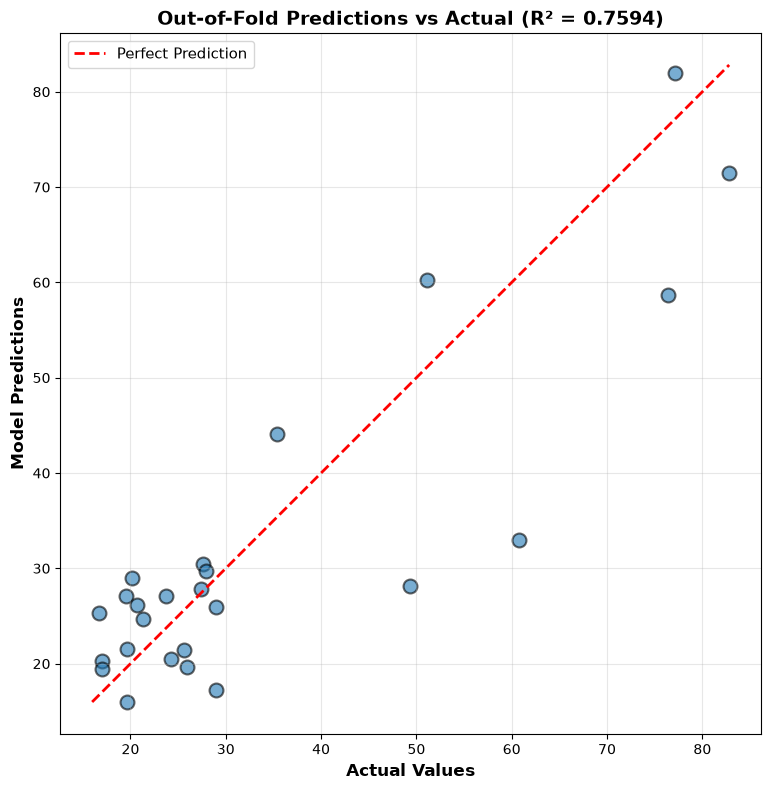

In [8]:
# print out actual vs out of fold prediction and show R^2
import matplotlib.pyplot as plt

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

# Create plot
fig, ax = plt.subplots(figsize=(10, 8))

# Scatter plot
ax.scatter(val_actuals, val_predictions, s=100, alpha=0.6, edgecolors='black', linewidth=1.5)

# Perfect prediction line (y=x)
min_val = min(val_actuals + val_predictions)
max_val = max(val_actuals + val_predictions)
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')

# Labels and title
ax.set_xlabel('Actual Values', fontsize=12, fontweight='bold')
ax.set_ylabel('Model Predictions', fontsize=12, fontweight='bold')
ax.set_title(f'Out-of-Fold Predictions vs Actual (R² = {val_r2:.4f})', 
             fontsize=14, fontweight='bold')

# Grid and legend
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

# Equal aspect ratio for better comparison
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

In [9]:
# Create dataframe with predictions vs actuals
comparison_df = pd.DataFrame({
    'Actual': val_actuals,
    'Prediction': val_predictions,
    'Residual': np.array(val_actuals) - np.array(val_predictions),
    'Abs_Error': np.abs(np.array(val_actuals) - np.array(val_predictions))
})

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

print("\n" + "="*70)
print("OUT-OF-FOLD VALIDATION PREDICTIONS")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70)
print(f"R² Score: {val_r2:.4f}")
print(f"Mean Absolute Error: {comparison_df['Abs_Error'].mean():.4f}")
print(f"RMSE: {np.sqrt(np.mean(comparison_df['Residual']**2)):.4f}")
print("="*70)


OUT-OF-FOLD VALIDATION PREDICTIONS
   Actual  Prediction  Residual  Abs_Error
23.680000   27.125926 -3.445926   3.445926
24.258481   20.518151  3.740329   3.740329
21.329450   24.703313 -3.373863   3.373863
20.183592   29.033972 -8.850380   8.850380
27.585357   30.492996 -2.907639   2.907639
27.921901   29.766953 -1.845051   1.845051
51.133703   60.203626 -9.069923   9.069923
82.812461   71.507236 11.305225  11.305225
77.134354   81.951661 -4.817307   4.817307
76.406460   58.727319 17.679141  17.679141
35.349977   44.058890 -8.708913   8.708913
19.560000   27.118702 -7.558702   7.558702
19.610000   21.499668 -1.889668   1.889668
16.730000   25.324833 -8.594833   8.594833
16.970000   20.330812 -3.360812   3.360812
17.040000   19.404208 -2.364208   2.364208
19.620000   15.980181  3.639819   3.639819
29.008360   25.977391  3.030969   3.030969
27.359952   27.844329 -0.484377   0.484377
20.681917   26.118384 -5.436467   5.436467
25.887025   19.666510  6.220515   6.220515
28.978707   17.260